# Péndulo de Furuta: prueba de un controlador sobre el modelo continuo no lineal

Se usa `furuta_c` de [furuta_nlsys.py](furuta_nlsys.py): el modelo continuo no lineal del stepper comandado en aceleración, con saturación de velocidad (y windup del integrador del firmware) y salidas cuantizadas como las lee el Arduino.

- Entrada $u$: aceleración enviada al Arduino en **[rev/s²]**.
- Salidas: $\theta$ (brazo) y $\varphi$ (péndulo) en [rad]; $\varphi = \pi$ es el péndulo invertido.

El controlador se arma como un sistema `nlsys` aparte y se cierra el lazo con `ct.interconnect`, así se puede reemplazar por el diseño propio sin tocar el resto.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct

import furuta_nlsys as fm

fm.P

{'wn': 10.96,
 'xi': 0.008,
 'K': 12.1,
 'Ts_ard': 0.02,
 'w_max': 3.9269908169872414,
 'th_lim': 2.454369260617026,
 'kc': 0.0,
 'step_angle': 0.0009817477042468104,
 'enc_res': 0.003926990816987242,
 'n_sub': 20}

## Controlador (dummy proporcional)

Linealizando alrededor de $\varphi = \pi$ con $\delta = \varphi - \pi$ (y $\cos\varphi \approx -1$):

$$
\ddot\delta \approx \omega_n^2\,\delta - 2\xi\omega_n\dot\delta + 2\pi K\,u
$$

Con $u = -K_p\,\delta$ el péndulo queda "estable" si $2\pi K K_p > \omega_n^2$, es decir $K_p > \omega_n^2/(2\pi K)$. Sin acción derivativa el único amortiguamiento es el propio $\xi$, así que el lazo **oscila**: sirve sólo para probar la estructura.

Para probar otro diseño, reemplazar `ctrl_output` (y, si tiene estados, agregar una función de actualización como en `furuta_update_c`). La saturación $\pm255$ es la misma que aplica la PC en `furuta_swingup.ipynb`.

In [2]:
Kp_min = fm.P["wn"]**2 / (2*np.pi*fm.P["K"])
print(f"Kp mínimo = {Kp_min:.2f}")

def ctrl_output(t, x, u, params):
    theta, phi = u
    e = phi - params["phi_ref"]
    u_k = -params["Kp"] * e
    return [np.clip(u_k, -params["u_max"], params["u_max"])]

ctrl_P = ct.nlsys(
    None, ctrl_output, name="ctrl",
    inputs=["theta", "phi"], outputs=["u"],
    params=dict(Kp=3.0, phi_ref=np.pi, u_max=255.0),
)

lazo = ct.interconnect(
    [fm.furuta_c, ctrl_P], name="lazo", inplist=[],
    outlist=["furuta_c.theta", "furuta_c.phi", "ctrl.u"],
    outputs=["theta", "phi", "u"],
)
lazo

Kp mínimo = 1.58


<InterconnectedSystem lazo: [] -> ['theta', 'phi', 'u']>

## Respuesta a perturbaciones en $\varphi$

La perturbación se aplica como condición inicial: el péndulo arranca desplazado $\delta_0$ de la vertical, en reposo y con el brazo quieto. `max_step` chico porque las salidas están cuantizadas (paso del stepper y del encoder).

In [3]:
t = np.arange(0, 5, 1e-3)
perturbaciones = [2, 5, 10, 20]   # [grados]

def simular(delta0_deg, **params):
    x0 = [0, 0, np.pi + np.deg2rad(delta0_deg), 0]
    return ct.input_output_response(lazo, t, 0, x0, params=params,
                                    solve_ivp_kwargs=dict(max_step=1e-3))

resp = {d: simular(d) for d in perturbaciones}

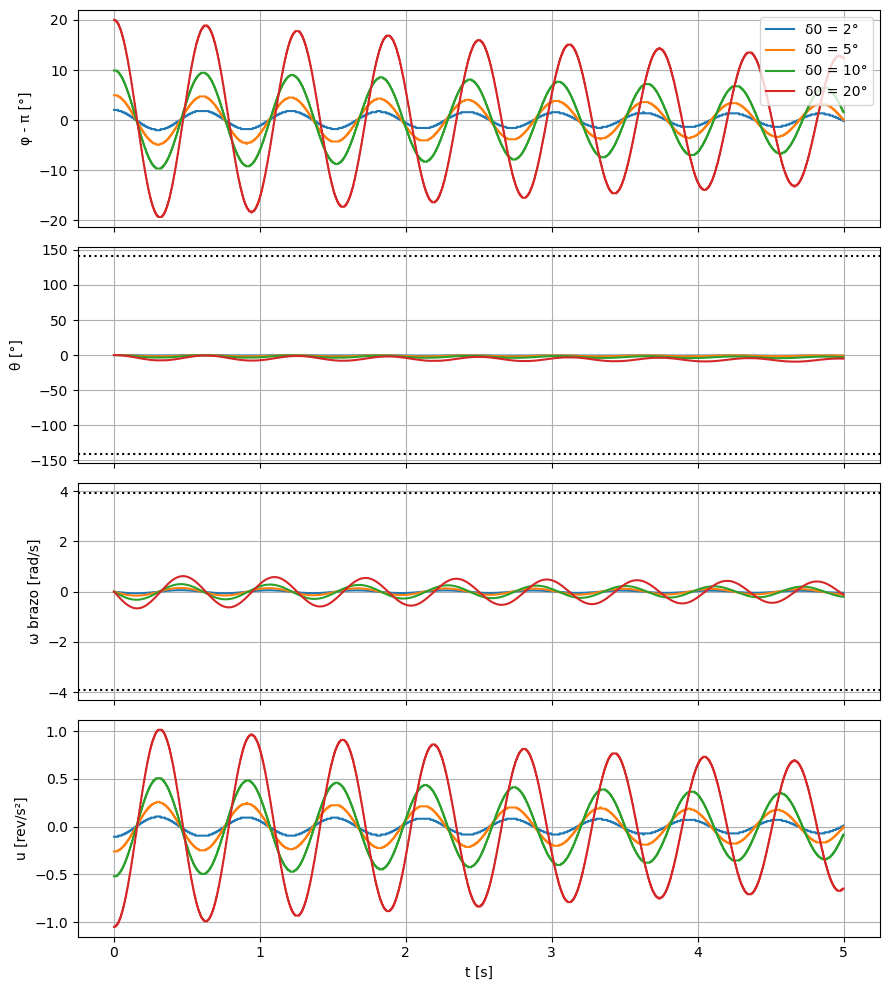

In [4]:
fig, ax = plt.subplots(4, 1, figsize=(9, 10), sharex=True)
for d, r in resp.items():
    th, phi, u = r.outputs
    v = r.states[1]
    ax[0].plot(r.time, np.rad2deg(phi - np.pi), label=f"δ0 = {d}°")
    ax[1].plot(r.time, np.rad2deg(th))
    ax[2].plot(r.time, np.clip(v, -fm.P["w_max"], fm.P["w_max"]))
    ax[3].plot(r.time, u)

ax[0].set_ylabel("φ - π [°]"); ax[0].legend(loc="upper right")
ax[1].set_ylabel("θ [°]")
ax[1].axhline(np.rad2deg(fm.P["th_lim"]), ls=":", c="k"); ax[1].axhline(-np.rad2deg(fm.P["th_lim"]), ls=":", c="k")
ax[2].set_ylabel("ω brazo [rad/s]")
ax[2].axhline(fm.P["w_max"], ls=":", c="k"); ax[2].axhline(-fm.P["w_max"], ls=":", c="k")
ax[3].set_ylabel("u [rev/s²]"); ax[3].set_xlabel("t [s]")
for a in ax: a.grid(True)
plt.tight_layout()

## Observaciones

- Con $K_p$ solo el péndulo no se cae, pero oscila casi sin amortiguar a $\approx\sqrt{2\pi K K_p - \omega_n^2}$ rad/s; la oscilación decae lentamente sólo por $\xi$. Con estas perturbaciones la velocidad del brazo queda lejos de $\omega_{max}$; probar perturbaciones más grandes o un $K_p$ mayor para ver la saturación.
- El brazo no se controla: $\theta$ queda libre (doble integrador), y en el equipo real el firmware lo frena en $\pm 140{,}6°$. Un diseño completo tiene que realimentar también $\theta$.
- `furuta_c` es una aproximación continua: no tiene el límite de ángulo, ni la velocidad en escalera cada $T_s = 20$ ms, ni la muestra de retardo del lazo serie. Antes de llevarlo al equipo conviene probar el diseño discretizado sobre el modelo discreto `fm.furuta`.

## Lazo abierto: perturbación en $\varphi$ en la posición inferior

Sin control ($u = 0$) el brazo queda quieto y el péndulo, apartado $\varphi_0$ de la posición colgada ($\varphi = 0$), oscila libremente:

$$
\ddot\varphi = -2\xi\omega_n\dot\varphi - \omega_n^2\sin\varphi
$$

Para ángulos chicos es un sistema de segundo orden con frecuencia $\omega_n\sqrt{1-\xi^2}$ y envolvente $\varphi_0\,e^{-\xi\omega_n t}$. Para ángulos grandes el $\sin\varphi$ alarga el período.

In [5]:
t_la = np.arange(0, 20, 1e-3)
perturbaciones_la = [5, 30, 90, 150]   # [grados]

def simular_la(phi0_deg, **params):
    x0 = [0, 0, np.deg2rad(phi0_deg), 0]
    return ct.input_output_response(fm.furuta_c, t_la, 0, x0, params=params,
                                    solve_ivp_kwargs=dict(max_step=1e-2))

resp_la = {d: simular_la(d) for d in perturbaciones_la}

wn, xi = fm.P["wn"], fm.P["xi"]
T_lin = 2*np.pi / (wn*np.sqrt(1 - xi**2))
for d, r in resp_la.items():
    phi = r.states[2]
    cruces = r.time[1:][(phi[:-1] > 0) & (phi[1:] <= 0)]   # cruces descendentes por 0
    print(f"φ0 = {d:3d}°  primer período = {cruces[1] - cruces[0]:.4f} s   (lineal: {T_lin:.4f} s)")

φ0 =   5°  primer período = 0.5730 s   (lineal: 0.5733 s)
φ0 =  30°  primer período = 0.5830 s   (lineal: 0.5733 s)
φ0 =  90°  primer período = 0.6650 s   (lineal: 0.5733 s)
φ0 = 150°  primer período = 0.8780 s   (lineal: 0.5733 s)


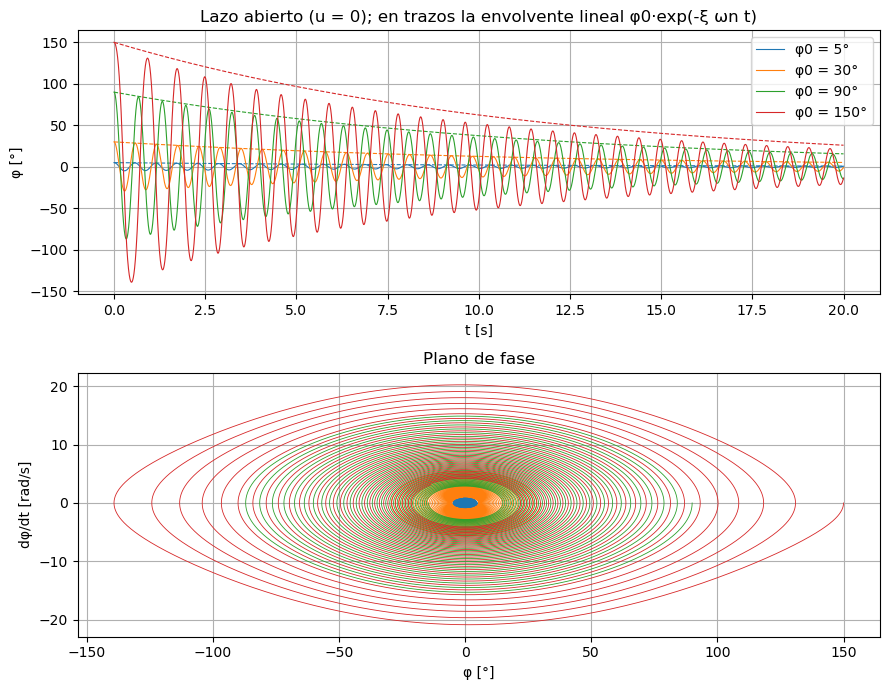

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(9, 7))
for d, r in resp_la.items():
    phi, dphi = r.states[2], r.states[3]
    l, = ax[0].plot(r.time, np.rad2deg(phi), lw=0.8, label=f"φ0 = {d}°")
    ax[0].plot(r.time, d*np.exp(-xi*wn*r.time), ls="--", c=l.get_color(), lw=0.8)
    ax[1].plot(np.rad2deg(phi), dphi, lw=0.6, c=l.get_color())

ax[0].set_xlabel("t [s]"); ax[0].set_ylabel("φ [°]")
ax[0].set_title("Lazo abierto (u = 0); en trazos la envolvente lineal φ0·exp(-ξ ωn t)")
ax[0].legend(loc="upper right")
ax[1].set_xlabel("φ [°]"); ax[1].set_ylabel("dφ/dt [rad/s]"); ax[1].set_title("Plano de fase")
for a in ax: a.grid(True)
plt.tight_layout()

## Modelo lineal continuo identificado (péndulo colgado)

`fm.furuta_lin` es el modelo identificado alrededor de la posición estable, escrito como `nlsys` con las mismas entradas y salidas que los otros modelos:

$$
\frac{\theta(s)}{u(s)} = \frac{k_{stepper}}{s^2}, \qquad
\frac{\varphi(s)}{u(s)} = \frac{k}{s^2 + 2\xi\omega_n s + \omega_n^2}
$$

con $k_{stepper} = 7221$, $k = 12.1$, $\xi = 0.008$ y $\omega_n = 10.956$ rad/s. Se verifica que las transferencias del `nlsys` sean las identificadas:

In [7]:
fm.P_lin, ct.ss2tf(ct.linearize(fm.furuta_lin, [0, 0, 0, 0], [0]))

({'kstepper': 7221.0, 'k': 12.1, 'xi': 0.008, 'wn': 10.956},
 TransferFunction(
 [[array([7221.])],
  [array([12.1])]],
 [[array([ 1.00000000e+00, -7.82139665e-17,  1.21113490e-20])],
  [array([  1.      ,   0.175296, 120.033936])]],
 outputs=2, inputs=1))

### Perturbación en $\varphi$ (lazo abierto, $u = 0$)

Se aparta el péndulo $\varphi_0$ de la posición colgada y se lo suelta. Se compara con el modelo no lineal `furuta_c` para la misma perturbación: para ángulos chicos coinciden, y para ángulos grandes el lineal no reproduce el alargamiento del período.

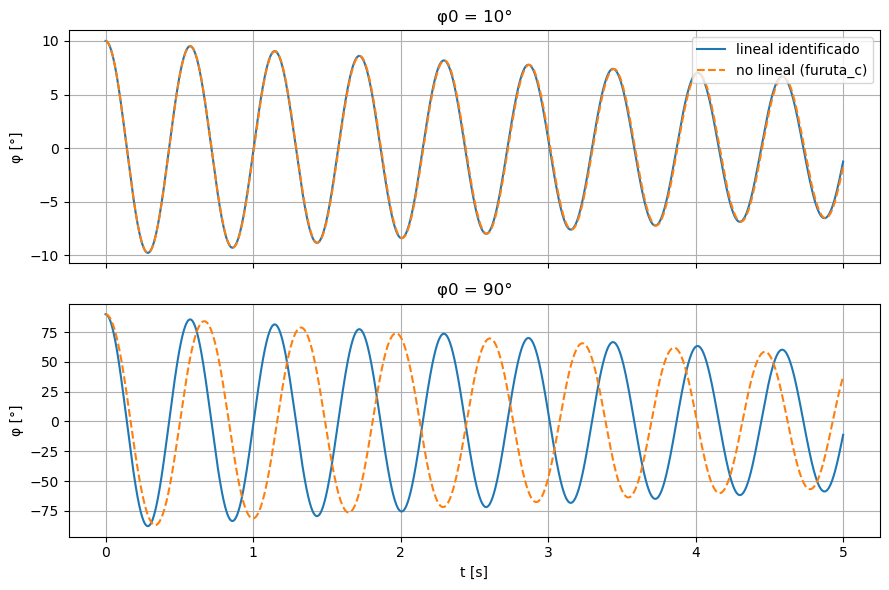

In [8]:
t_lin = np.arange(0, 5, 1e-3)
perturbaciones_lin = [10, 90]   # [grados]

fig, ax = plt.subplots(len(perturbaciones_lin), 1, figsize=(9, 6), sharex=True)
for a, d in zip(ax, perturbaciones_lin):
    phi0 = np.deg2rad(d)
    r_lin = ct.input_output_response(fm.furuta_lin, t_lin, 0, [0, 0, phi0, 0])
    r_nl = ct.input_output_response(fm.furuta_c, t_lin, 0, [0, 0, phi0, 0],
                                    solve_ivp_kwargs=dict(max_step=1e-2))
    a.plot(t_lin, np.rad2deg(r_lin.states[2]), label="lineal identificado")
    a.plot(t_lin, np.rad2deg(r_nl.states[2]), "--", label="no lineal (furuta_c)")
    a.set_ylabel("φ [°]"); a.set_title(f"φ0 = {d}°"); a.grid(True)
ax[0].legend(loc="upper right"); ax[-1].set_xlabel("t [s]")
plt.tight_layout()

### Simulación de `furuta_lin` con perturbaciones en $\varphi$

Mismas perturbaciones que en el lazo cerrado, pero ahora sobre el modelo lineal identificado, que está linealizado en la posición **colgada**: la condición inicial es $\varphi_0 = \delta_0$ (no $\pi + \delta_0$). Con $u = 0$ el brazo no se mueve ($\theta = 0$) y el péndulo oscila a $\omega_n\sqrt{1-\xi^2}$ con envolvente $\delta_0\,e^{-\xi\omega_n t}$ (en trazos).

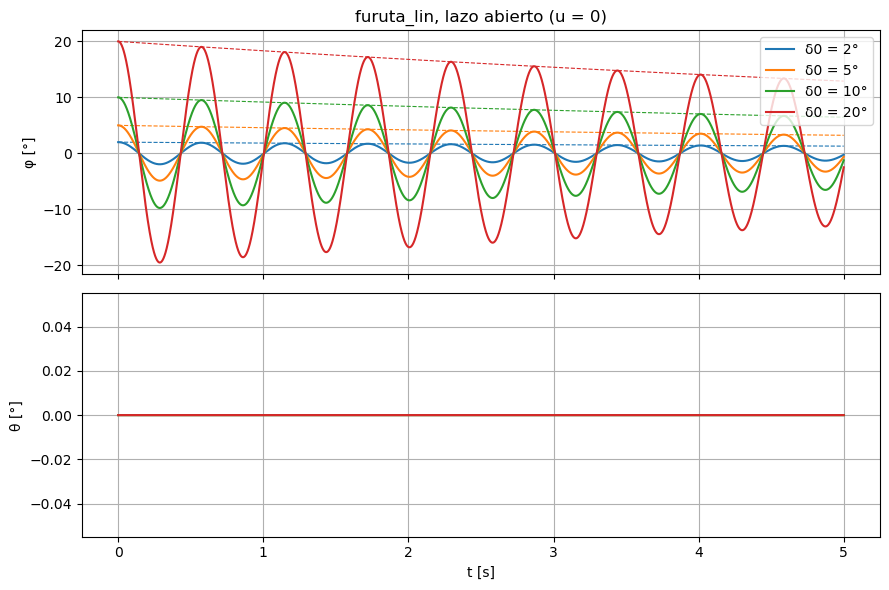

In [9]:
t_lin2 = np.arange(0, 5, 1e-3)
resp_lin = {d: ct.input_output_response(fm.furuta_lin, t_lin2, 0, [0, 0, np.deg2rad(d), 0])
            for d in perturbaciones}

wn_l, xi_l = fm.P_lin["wn"], fm.P_lin["xi"]
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for d, r in resp_lin.items():
    th, phi = r.outputs
    l, = ax[0].plot(r.time, np.rad2deg(phi), label=f"δ0 = {d}°")
    ax[0].plot(r.time, d*np.exp(-xi_l*wn_l*r.time), ls="--", lw=0.8, c=l.get_color())
    ax[1].plot(r.time, np.rad2deg(th), c=l.get_color())

ax[0].set_ylabel("φ [°]"); ax[0].legend(loc="upper right")
ax[0].set_title("furuta_lin, lazo abierto (u = 0)")
ax[1].set_ylabel("θ [°]"); ax[1].set_xlabel("t [s]")
for a in ax: a.grid(True)
plt.tight_layout()